# Project Title

# 🍔 Indian Food Delivery Analysis
### Exploring Customer Behavior, Order Patterns and Delivery Performance

## 📌 Problem Statement

- The online food delivery industry generates a large amount of data related to customers, restaurants, food categories, order amounts, delivery times, ratings, discounts, and payment methods.

- This project aims to perform Exploratory Data Analysis (EDA) on the Indian Food Delivery dataset to understand customer ordering behavior, identify popular food categories and cities, analyze delivery performance, examine the impact of discounts, and discover important patterns that can help food delivery businesses improve customer satisfaction and operational efficiency.

## 🎯 Why This Project?

The food delivery industry is growing rapidly in India. Companies need to understand customer preferences, restaurant performance, delivery efficiency, and order patterns.

This dataset provides multiple business-related variables such as:

- Customer information
- City
- Restaurant
- Food category
- Order amount
- Discounts
- Delivery distance
- Estimated and actual delivery time
- Customer ratings
- Payment methods
- Order status

Analyzing these factors can help businesses make better decisions and improve customer experience.

## 🎯 Project Objectives

The main objectives of this project are:

1. To understand the structure and quality of the dataset.
2. To clean missing, duplicate, and inconsistent data.
3. To identify popular food categories.
4. To analyze customer ordering behavior.
5. To identify cities with higher order activity.
6. To analyze order amounts and discounts.
7. To compare estimated and actual delivery times.
8. To study customer and restaurant ratings.
9. To analyze payment method preferences.
10. To identify factors affecting delivery performance.
11. To discover useful business insights and recommendations.

In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

# Data Observation

In [3]:
# Loading dataset 
df = pd.read_csv("Indian_Food_Delivery_.csv")
# first 5 lines print 
df.head()
# Last 5 lines print
df.tail()

,Order_ID,Customer_ID,Customer_Name,City,Restaurant_Name,Food_Category,Order_Date,Order_Time,Order_Amount,Discount_Percent,Delivery_Fee,Delivery_Distance_km,Estimated_Delivery_Min,Actual_Delivery_Min,Customer_Rating,Payment_Method,Order_Status,Restaurant_Rating,Customer_Age,Customer_Gender
49995,ORD122003,CUST05891,NaN,Delhi,Restaurant_171,Desserts,2025-06-25,14:31,576.32,0,0,2.45,54,22,2.7,Cash,Delivered,4.8,23.0,Other
49996,ORD147550,CUST08076,Customer_6987,Ahmedabad,Restaurant_103,South Indian,2024-10-28,20:28,334.32,5,0,0.96,50,113,3.2,Debit Card,Delivered,4.6,NaN,Male
49997,ORD120589,CUST03202,Customer_1576,Mumbai,Restaurant_98,Chinese,2026-05-11,04:11,1823.78,15,40,12.49,28,113,3.3,Wallet,Delivered,3.4,34.0,male
49998,ORD125003,CUST06724,Customer_2830,Delhi,Restaurant_150,Chinese,2024-06-03,06:22,658.48,25,40,2.05,49,46,1.5,Cash,Delivered,4.5,57.0,Other
49999,ORD137936,CUST07273,Customer_2290,Mumbai,Restaurant_169,Biryani,2025-06-20,00:21,1080.29,5,50,4.91,68,57,3.5,Wallet,Delivered,3.9,39.0,male


In [4]:
# Dataset shape 
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 50000
Number of Columns: 20


## Data Understanding 

### Column Names

In [5]:
df.columns

Index(['Order_ID', 'Customer_ID', 'Customer_Name', 'City', 'Restaurant_Name',
       'Food_Category', 'Order_Date', 'Order_Time', 'Order_Amount',
       'Discount_Percent', 'Delivery_Fee', 'Delivery_Distance_km',
       'Estimated_Delivery_Min', 'Actual_Delivery_Min', 'Customer_Rating',
       'Payment_Method', 'Order_Status', 'Restaurant_Rating', 'Customer_Age',
       'Customer_Gender'],
      dtype='object')

### Dataset Information 

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                50000 non-null  object 
 1   Customer_ID             50000 non-null  object 
 2   Customer_Name           48500 non-null  object 
 3   City                    48501 non-null  object 
 4   Restaurant_Name         50000 non-null  object 
 5   Food_Category           48495 non-null  object 
 6   Order_Date              50000 non-null  object 
 7   Order_Time              50000 non-null  object 
 8   Order_Amount            50000 non-null  float64
 9   Discount_Percent        50000 non-null  int64  
 10  Delivery_Fee            50000 non-null  int64  
 11  Delivery_Distance_km    50000 non-null  float64
 12  Estimated_Delivery_Min  50000 non-null  int64  
 13  Actual_Delivery_Min     50000 non-null  int64  
 14  Customer_Rating         48502 non-null

### Statistical Summary 

In [7]:
df.describe()

,Order_Amount,Discount_Percent,Delivery_Fee,Delivery_Distance_km,Estimated_Delivery_Min,Actual_Delivery_Min,Customer_Rating,Restaurant_Rating,Customer_Age
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,48502.000000,50000.000000,48509.000000
mean,779.896166,12.512400,33.298800,5.316773,47.006640,66.716340,3.002101,3.752322,45.160609
std,869.792025,8.517411,19.641936,11.969710,15.873568,30.392745,1.155066,0.723231,17.127983
min,13.250000,0.000000,0.000000,0.000000,20.000000,15.000000,1.000000,2.500000,5.000000
25%,432.190000,5.000000,20.000000,1.450000,33.000000,40.000000,2.000000,3.100000,30.000000
50%,669.425000,15.000000,30.000000,3.450000,47.000000,67.000000,3.000000,3.800000,45.000000
75%,981.950000,20.000000,50.000000,6.900000,61.000000,93.000000,4.000000,4.400000,60.000000
max,29973.577635,25.000000,60.000000,488.218169,74.000000,119.000000,5.000000,5.000000,150.000000


### Include categorical columns

In [8]:
df.describe(include="all")

,Order_ID,Customer_ID,Customer_Name,City,Restaurant_Name,Food_Category,Order_Date,Order_Time,Order_Amount,Discount_Percent,Delivery_Fee,Delivery_Distance_km,Estimated_Delivery_Min,Actual_Delivery_Min,Customer_Rating,Payment_Method,Order_Status,Restaurant_Rating,Customer_Age,Customer_Gender
count,50000,50000,48500,48501,50000,48495,50000,50000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,48502.000000,48497,50000,50000.000000,48509.000000,50000
unique,49751,9940,9922,14,300,7,900,1440,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7,5,NaN,NaN,5
top,ORD116389,CUST05850,Customer_3820,Nashik,Restaurant_2,North Indian,2026-03-04,02:10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,UPI,Delivered,NaN,NaN,Other
freq,2,15,16,3527,208,7028,82,56,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7024,39121,NaN,NaN,10096
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,779.896166,12.512400,33.298800,5.316773,47.006640,66.716340,3.002101,NaN,NaN,3.752322,45.160609,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,869.792025,8.517411,19.641936,11.969710,15.873568,30.392745,1.155066,NaN,NaN,0.723231,17.127983,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.250000,0.000000,0.000000,0.000000,20.000000,15.000000,1.000000,NaN,NaN,2.500000,5.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,432.190000,5.000000,20.000000,1.450000,33.000000,40.000000,2.000000,NaN,NaN,3.100000,30.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,669.425000,15.000000,30.000000,3.450000,47.000000,67.000000,3.000000,NaN,NaN,3.800000,45.000000,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,981.950000,20.000000,50.000000,6.900000,61.000000,93.000000,4.000000,NaN,NaN,4.400000,60.000000,NaN


### Column Explanation

# Data Cleaning

### Convert Column Names to Lowercase

In [9]:
df.columns = df.columns.str.lower()
df.columns

Index(['order_id', 'customer_id', 'customer_name', 'city', 'restaurant_name',
       'food_category', 'order_date', 'order_time', 'order_amount',
       'discount_percent', 'delivery_fee', 'delivery_distance_km',
       'estimated_delivery_min', 'actual_delivery_min', 'customer_rating',
       'payment_method', 'order_status', 'restaurant_rating', 'customer_age',
       'customer_gender'],
      dtype='object')

### Check Missing Values

In [10]:
df.isnull().sum()

order_id                     0
customer_id                  0
customer_name             1500
city                      1499
restaurant_name              0
food_category             1505
order_date                   0
order_time                   0
order_amount                 0
discount_percent             0
delivery_fee                 0
delivery_distance_km         0
estimated_delivery_min       0
actual_delivery_min          0
customer_rating           1498
payment_method            1503
order_status                 0
restaurant_rating            0
customer_age              1491
customer_gender              0
dtype: int64

In [11]:
text_cols = ["city", "payment_method", "food_category", "customer_name", "order_status", "customer_gender"]
for col in text_cols:
    df[col] = df[col].astype(str).str.strip().str.title()
    df[col] = df[col].replace({"Nan": np.nan, "None": np.nan})


categorical_cols = ["customer_name", "city", "food_category", "payment_method"]
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])


numerical_cols = ["customer_rating"]

for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

### Percentage of Missing Values

In [12]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_data = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": missing_percentage
})

missing_data[missing_data["Missing Values"] > 0]

,Missing Values,Percentage
customer_age,1491,2.982


# Handling Missing Values

### Categorical columns
- For categorical variables, use the mode because these columns contain categories.

In [13]:
categorical_cols = ["customer_name","city","food_category","payment_method"]

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])
df[categorical_cols].isnull().sum()

customer_name     0
city              0
food_category     0
payment_method    0
dtype: int64

## Numerical columns

- Use the median because it is less affected by extreme values.

In [14]:
numerical_cols = ["customer_rating","customer_age"]

for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

df[numerical_cols].isnull().sum()

customer_rating    0
customer_age       0
dtype: int64

# Check Duplicate Records

In [15]:
print(df.duplicated().sum())

249


### Remove Duplicates

In [16]:
# Drop Duplicates
print("Duplicates before:", df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicates after:", df.duplicated().sum())

Duplicates before: 249
Duplicates after: 0


# Check Unique Values

In [17]:
df["city"].unique()

array(['Chennai', 'Pune', 'Mumbai', 'Delhi', 'Jaipur', 'Ahmedabad',
       'Kolkata', 'Nashik', 'Bengaluru', 'Hyderabad'], dtype=object)

In [18]:
df["payment_method"].unique()

array(['Debit Card', 'Wallet', 'Upi', 'Cash', 'Credit Card'], dtype=object)

In [19]:
df["order_status"].unique()

array(['Delivered', 'Pending', 'Cancelled'], dtype=object)

In [20]:
df["customer_gender"].unique()

array(['Other', 'Female', 'Male'], dtype=object)

# Clean Inconsistent Categorical Values

### City

In [21]:
df["city"] = df["city"].str.strip().str.title()

In [22]:
df["city"].unique()

array(['Chennai', 'Pune', 'Mumbai', 'Delhi', 'Jaipur', 'Ahmedabad',
       'Kolkata', 'Nashik', 'Bengaluru', 'Hyderabad'], dtype=object)

## Payment Method

In [23]:
df["payment_method"] = df["payment_method"].str.strip().str.title()

## Order Status

In [24]:
df["order_status"] = df["order_status"].str.strip().str.title()

## Customer gender

In [25]:
df["customer_gender"] = df["customer_gender"].str.strip().str.title()

In [26]:
print(df["city"].unique())

print(df["payment_method"].unique())

print(df["order_status"].unique())

print(df["customer_gender"].unique())

['Chennai' 'Pune' 'Mumbai' 'Delhi' 'Jaipur' 'Ahmedabad' 'Kolkata' 'Nashik'
 'Bengaluru' 'Hyderabad']
['Debit Card' 'Wallet' 'Upi' 'Cash' 'Credit Card']
['Delivered' 'Pending' 'Cancelled']
['Other' 'Female' 'Male']


# Convert Date Column

In [27]:
df["order_date"] = pd.to_datetime(df["order_date"])

df["order_date"].dtype

dtype('<M8[ns]')

# 🚨️ Outlier Detection
- We should first visualize outliers before removing anything.

## Numerical Columns

In [28]:
num_cols = df.select_dtypes(include=np.number).columns
num_cols

Index(['order_amount', 'discount_percent', 'delivery_fee',
       'delivery_distance_km', 'estimated_delivery_min', 'actual_delivery_min',
       'customer_rating', 'restaurant_rating', 'customer_age'],
      dtype='object')

## Boxplots

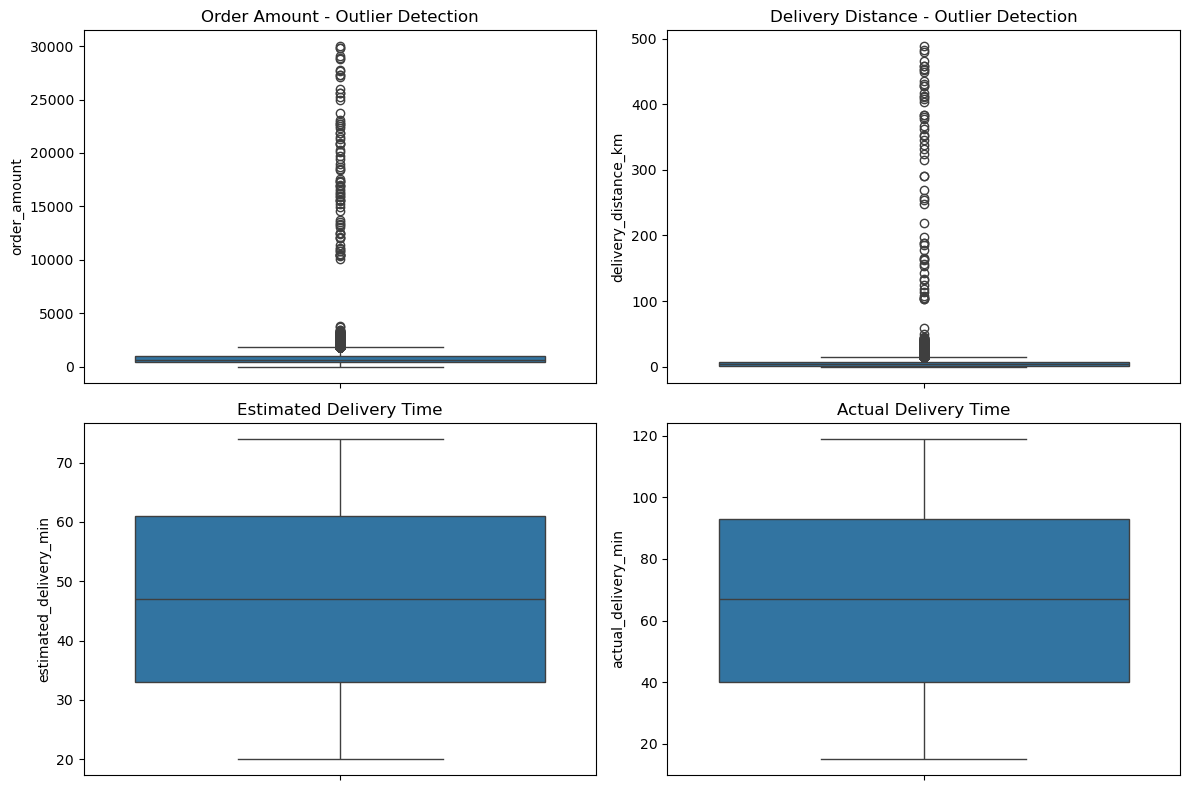

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.boxplot(y=df["order_amount"], ax=axes[0, 0])
axes[0, 0].set_title("Order Amount - Outlier Detection")

sns.boxplot(y=df["delivery_distance_km"], ax=axes[0, 1])
axes[0, 1].set_title("Delivery Distance - Outlier Detection")

sns.boxplot(y=df["estimated_delivery_min"], ax=axes[1, 0])
axes[1, 0].set_title("Estimated Delivery Time")

sns.boxplot(y=df["actual_delivery_min"], ax=axes[1, 1])
axes[1, 1].set_title("Actual Delivery Time")

plt.tight_layout()
plt.show()

# IQR Method

In [30]:
def detect_outliers(data, column):
    
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    
    return outliers, lower_bound, upper_bound

## Check important variables

In [31]:
columns_to_check = [ "order_amount","delivery_distance_km","customer_age","actual_delivery_min"]

for col in columns_to_check:
    
    outliers, lower, upper = detect_outliers(df, col)
    
    print("\nColumn:", col)
    print("Number of Outliers:", len(outliers))
    print("Lower Bound:", lower)
    print("Upper Bound:", upper)


Column: order_amount
Number of Outliers: 1383
Lower Bound: -391.1075000000001
Upper Bound: 1804.8725

Column: delivery_distance_km
Number of Outliers: 2424
Lower Bound: -6.7250000000000005
Upper Bound: 15.075000000000001

Column: customer_age
Number of Outliers: 27
Lower Bound: -11.0
Upper Bound: 101.0

Column: actual_delivery_min
Number of Outliers: 0
Lower Bound: -39.5
Upper Bound: 172.5


### Important: Logical Outlier Treatment

⚠️ Don't blindly remove all IQR outliers.

For example:

Customer Age

Values such as 150 years are clearly unrealistic and should be treated as invalid.

In [32]:
# Check Customer Age outliers
df["customer_age"].describe()

count    49751.000000
mean        45.145665
std         16.865622
min          5.000000
25%         31.000000
50%         45.000000
75%         59.000000
max        150.000000
Name: customer_age, dtype: float64

In [33]:
df[df["customer_age"] > 100][["customer_age"]]

,customer_age
2835,120.0
2898,120.0
4431,120.0
4562,150.0
7350,120.0
9282,120.0
10103,120.0
11417,150.0
11915,120.0
13306,150.0


In [34]:
df.loc[df["customer_age"] > 100, "customer_age"] = np.nan
df["customer_age"] = df["customer_age"].fillna(df["customer_age"].median())

In [35]:
df["customer_age"].describe()

count    49751.000000
mean        45.097727
std         16.736355
min          5.000000
25%         31.000000
50%         45.000000
75%         59.000000
max         74.000000
Name: customer_age, dtype: float64

## Delivery Distance 

In [36]:
print("Total records before treatment:", len(df))

# Treat unrealistic delivery distances
df.loc[df["delivery_distance_km"] > 40, "delivery_distance_km"] = np.nan

# Fill missing values with median
median_distance = df["delivery_distance_km"].median()
df["delivery_distance_km"] = df["delivery_distance_km"].fillna(median_distance)

print("Total records after treatment:", len(df))
print("Median distance used:", median_distance)
print("New maximum distance:", df["delivery_distance_km"].max())

Total records before treatment: 49751
Total records after treatment: 49751
Median distance used: 3.45
New maximum distance: 39.99


In [37]:
df_original = pd.read_csv("Indian_Food_Delivery_.csv")
print("Original rows:", len(df_original))

print("Values above 40 km:",
      (df_original["Delivery_Distance_km"] > 40).sum())

Original rows: 50000
Values above 40 km: 72


In [38]:
df_original[df_original["Delivery_Distance_km"] > 40][
    ["Order_ID", "City", "Delivery_Distance_km"]
].sort_values(
    by="Delivery_Distance_km",
    ascending=False
).head(20)

,Order_ID,City,Delivery_Distance_km
40150,ORD140150,pune,488.218169
49534,ORD149534,MUMBAI,482.135682
25820,ORD125820,Jaipur,480.169018
19765,ORD119765,pune,465.178706
8014,ORD108014,Ahmedabad,458.924198
42345,ORD142345,Delhi,458.727827
40559,ORD140559,Mumbai,454.403938
20005,ORD120005,Hyderabad,452.186674
15398,ORD115398,Jaipur,448.407294
36601,ORD136601,Mumbai,435.049599


# Logical Outlier Treatment for Delivery Distance

In [39]:
# Logical Outlier Treatment for Delivery Distance

print("Records before treatment:", len(df))

# Treat unrealistic delivery distances above 40 km as missing
df.loc[df["delivery_distance_km"] > 40, "delivery_distance_km"] = np.nan

# Impute using median
median_distance = df["delivery_distance_km"].median() 

df["delivery_distance_km"] = df["delivery_distance_km"].fillna(median_distance)

print("Records after treatment:", len(df))
print("Median distance used:", median_distance)
print("New maximum distance:", df["delivery_distance_km"].max())

Records before treatment: 49751
Records after treatment: 49751
Median distance used: 3.45
New maximum distance: 39.99


In [40]:
df["delivery_distance_km"].describe()

count    49751.000000
mean         4.963513
std          4.908183
min          0.000000
25%          1.450000
50%          3.450000
75%          6.870000
max         39.990000
Name: delivery_distance_km, dtype: float64

In [41]:
(df["delivery_distance_km"] > 40).sum()

np.int64(0)

In [42]:
df["delivery_distance_km"].max()

39.99

### Business explanation:

Customer age values outside a realistic human age range were considered data quality errors rather than genuine business observations. Therefore, invalid values were replaced with missing values and imputed using the median age.

For Order Amount and Delivery Distance, first inspect extreme records before deciding whether they should be removed.

# ⚖️ Check Dataset Imbalance

- Since this is mainly an EDA/business dataset, the most relevant categorical variable to check is:

In [43]:
df["order_status"].value_counts()

order_status
Delivered    43847
Cancelled     3948
Pending       1956
Name: count, dtype: int64

### Percentage Distribution 

In [44]:
(df["order_status"].value_counts(normalize=True) * 100).round(2)

order_status
Delivered    88.13
Cancelled     7.94
Pending       3.93
Name: proportion, dtype: float64

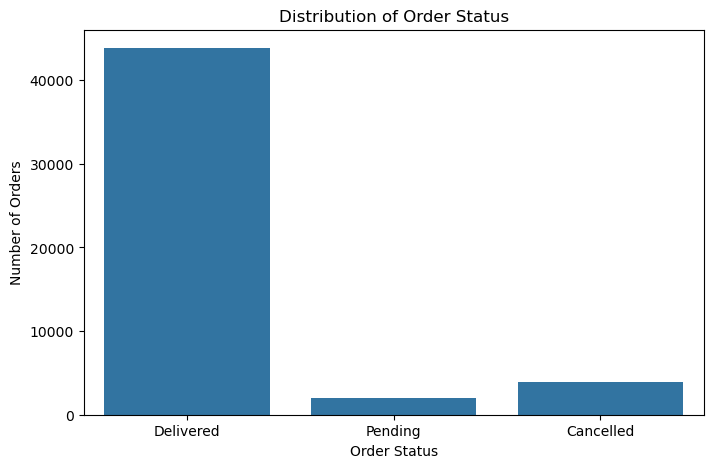

In [45]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="order_status"
)

plt.title("Distribution of Order Status")

plt.xlabel("Order Status")

plt.ylabel("Number of Orders")

plt.show()

### Order Status Imbalance

The order status distribution shows that most orders are delivered,
while cancelled and pending orders represent a much smaller proportion
of the dataset.

This indicates an imbalance in order status categories. Since this is
an EDA project and not a predictive modeling task, no resampling was
performed. The original distribution was retained for analysis.

# 📊 UNIVARIATE ANALYSIS

In [46]:
df["order_amount"].describe()

count    49751.000000
mean       779.459229
std        865.890094
min         13.250000
25%        432.385000
50%        669.380000
75%        981.380000
max      29973.577635
Name: order_amount, dtype: float64

### 1. Distribution of Order Amount

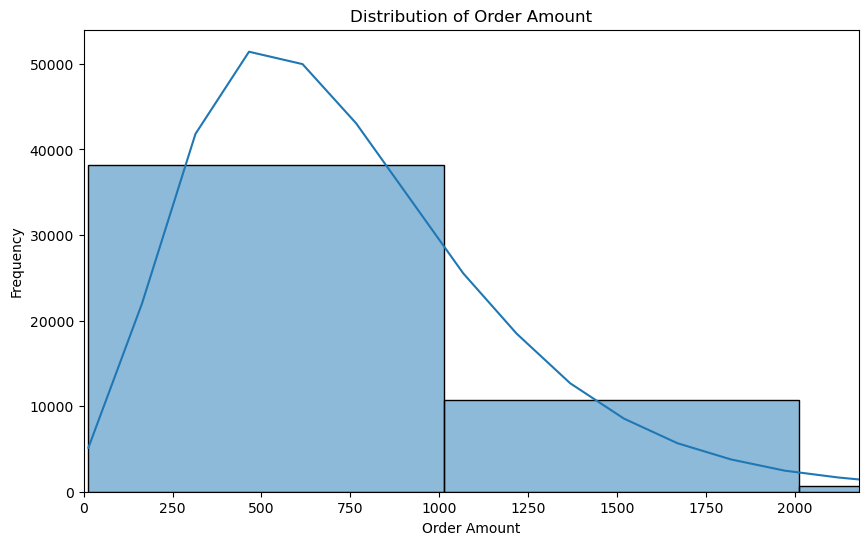

In [47]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="order_amount",
    bins=30,
    kde=True
)

plt.xlim(0, df["order_amount"].quantile(0.99))

plt.title("Distribution of Order Amount")
plt.xlabel("Order Amount")
plt.ylabel("Frequency")

plt.show()

### Observation

- Most orders are concentrated in the lower-to-middle order amount range.
- The distribution peaks around the ₹400–₹700 range.
- The frequency of orders decreases as the order amount increases.
- The distribution is positively skewed, indicating the presence of some higher-value orders.

## Why?

- Histogram is used to understand the distribution and frequency of order amounts.

## Observation:

- Write the observation after running the graph, based on your actual output.

## 2. Food Category Distribution

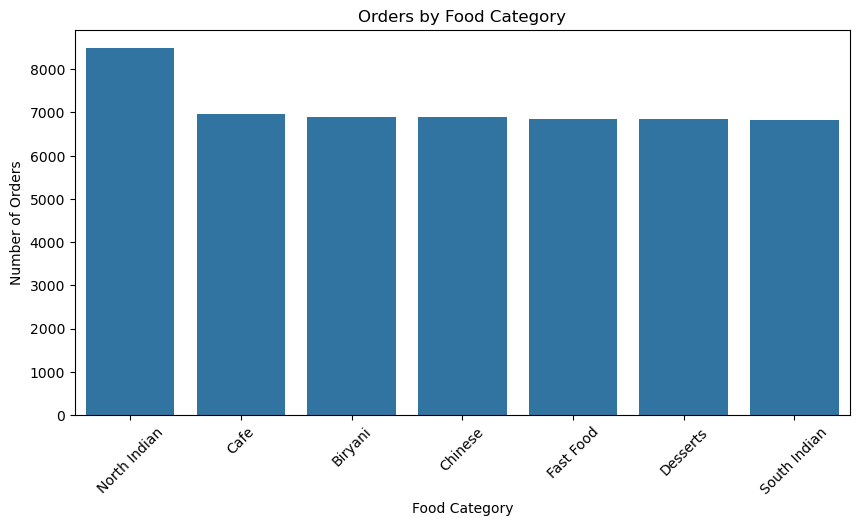

In [48]:
plt.figure(figsize=(10, 5))

order = df["food_category"].value_counts().index

sns.countplot(
    data=df,
    x="food_category",
    order=order
)

plt.xticks(rotation=45)

plt.title("Orders by Food Category")

plt.xlabel("Food Category")

plt.ylabel("Number of Orders")

plt.show()

### Observation

- North Indian is the most frequently ordered food category, with around 8,500 orders.
- The remaining food categories have relatively similar order volumes, mostly around 6,800–7,000 orders.
- This indicates that North Indian food has comparatively higher demand in the dataset.

# Business Insight:

- The most frequently ordered food category can help food delivery companies and restaurants prioritize inventory, promotions, and menu availability.

# 3. City-wise Orders

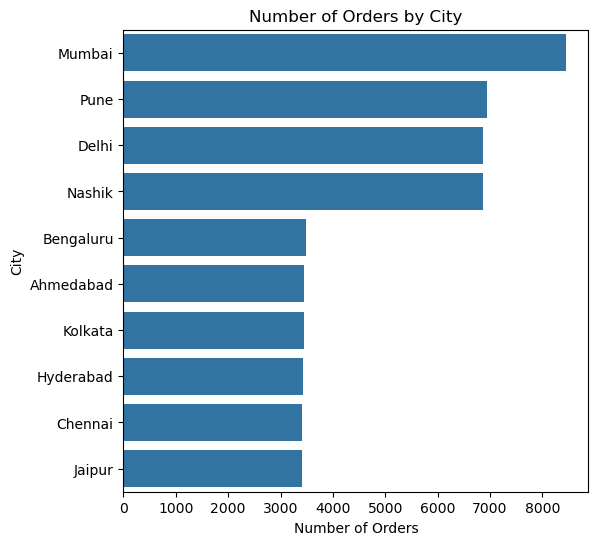

In [49]:
plt.figure(figsize=(6, 6))

city_order = df["city"].value_counts().index

sns.countplot(
    data=df,
    y="city",
    order=city_order
)

plt.title("Number of Orders by City")

plt.xlabel("Number of Orders")

plt.ylabel("City")

plt.show()

# 4. Payment Method Distribution

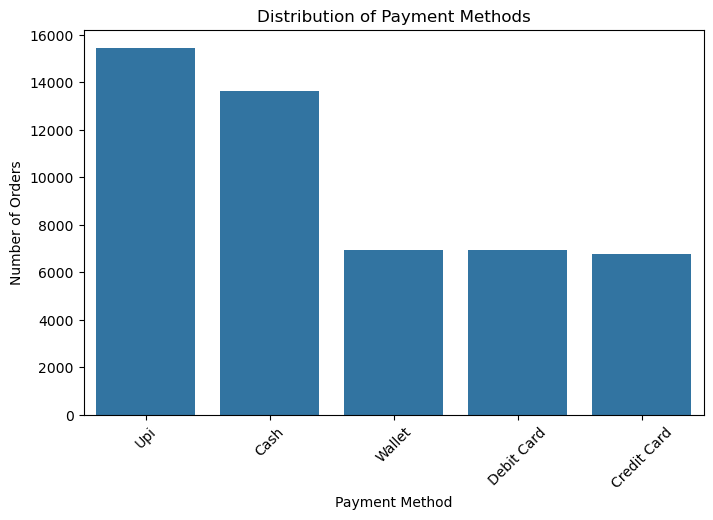

In [50]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="payment_method",
    order=df["payment_method"].value_counts().index
)

plt.xticks(rotation=45)

plt.title("Distribution of Payment Methods")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")

plt.show()

### Observation

- UPI is the most commonly used payment method, with approximately 15,500 orders.
- Cash is the second most used payment method, with around 13,600 orders.
- Wallet, Debit Card, and Credit Card have comparatively lower and similar order volumes.
- The distribution indicates a strong preference for UPI payments among customers.

# 5. Customer Gender Distribution

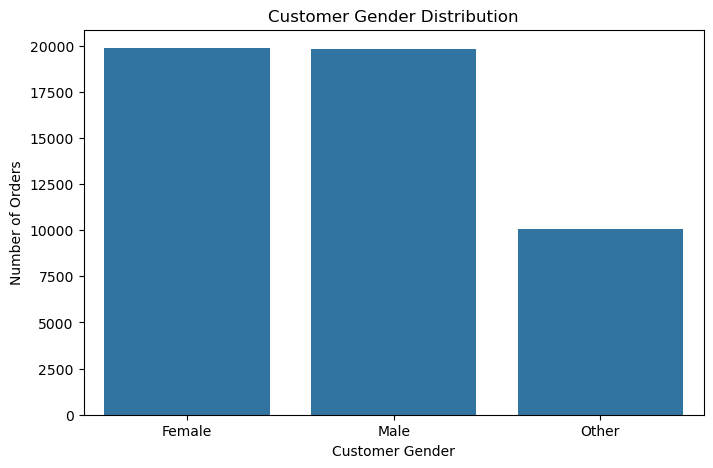

In [51]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="customer_gender",
    order=df["customer_gender"].value_counts().index
)

plt.title("Customer Gender Distribution")
plt.xlabel("Customer Gender")
plt.ylabel("Number of Orders")

plt.show()

### Observation

- Female and Male customers have nearly equal order counts, with approximately 20,000 orders each.
- The "Other" category has comparatively fewer orders, with around 10,000 orders.
- The distribution indicates that Male and Female customers are similarly represented in the dataset.

# 6. Customer Age Distribution

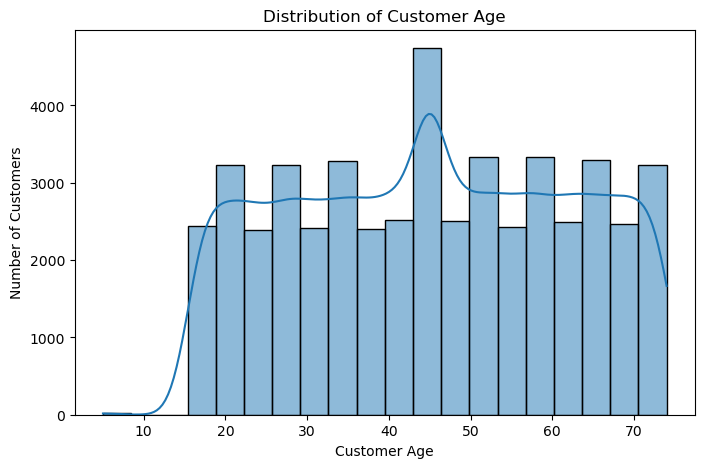

In [52]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="customer_age",
    bins=20,
    kde=True
)

plt.title("Distribution of Customer Age")
plt.xlabel("Customer Age")
plt.ylabel("Number of Customers")

plt.show()

### Observation

- Most customers are between approximately 20 and 70 years old.
- The distribution is fairly spread across the middle-age range.
- The highest concentration of customers is around the 40–50 years age group.
- Very few customers are present outside the main age range.

# 7. Customer Rating Distribution

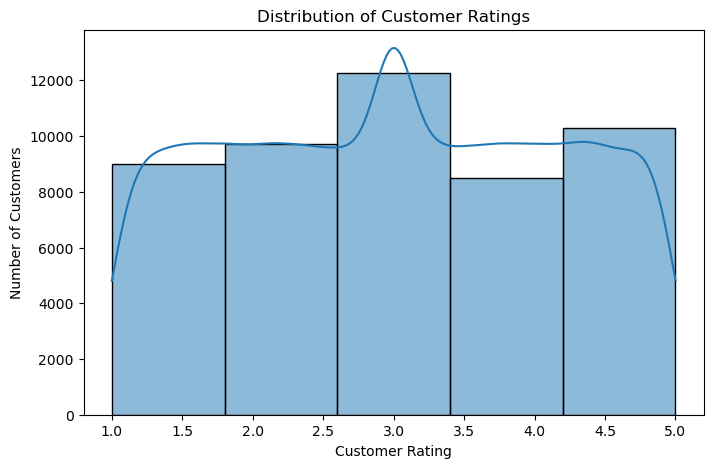

In [53]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="customer_rating",
    bins=5,
    kde=True
)

plt.title("Distribution of Customer Ratings")
plt.xlabel("Customer Rating")
plt.ylabel("Number of Customers")

plt.show()

### Observation

- Customer ratings range from 1 to 5.
- The highest number of ratings is observed around 3 stars.
- Ratings of 4 and 5 stars also have a substantial number of customers.
- 1-star ratings are comparatively less frequent.

# Age Group Analysis.

In [54]:
# Create customer age groups

df["age_group"] = pd.cut(
    df["customer_age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["≤25", "26-35", "36-45", "46-55", "56+"],
    include_lowest=True
)

age_group_spending = (
    df.groupby("age_group", observed=False)["order_amount"]
      .mean()
      .sort_values(ascending=False)
)

print(age_group_spending)

age_group
36-45    788.335977
56+      781.199038
≤25      781.119774
46-55    771.943511
26-35    771.462858
Name: order_amount, dtype: float64


### Observation

- The 36–45 age group has the highest average order amount of approximately ₹788.
- The 26–35 age group has the lowest average order amount of approximately ₹771.
- The 56+ and ≤25 age groups have similar average spending of around ₹781.
- The difference in average order amount across age groups is relatively small.

# 📈 BIVARIATE ANALYSIS

# 1. Food Category vs Average Order Amount

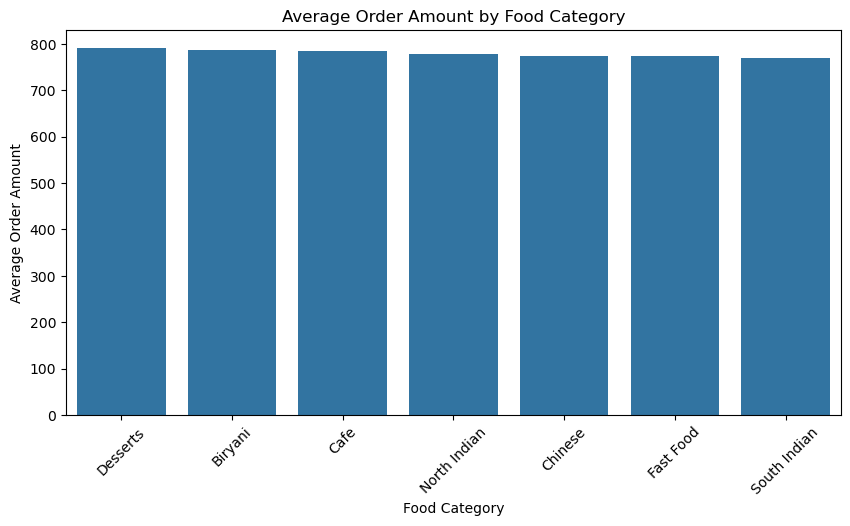

In [55]:
plt.figure(figsize=(10, 5))

avg_order_by_category = (
    df.groupby("food_category")["order_amount"]
      .mean()
      .sort_values(ascending=False)
)

sns.barplot(
    x=avg_order_by_category.index,
    y=avg_order_by_category.values
)

plt.xticks(rotation=45)
plt.title("Average Order Amount by Food Category")
plt.xlabel("Food Category")
plt.ylabel("Average Order Amount")

plt.show()

### Observation

- Desserts have the highest average order amount, at approximately ₹790.
- Biryani and Cafe also show relatively high average order amounts.
- South Indian has a comparatively lower average order amount.
- Overall, the difference in average order amount across food categories is relatively small.

# 2. City vs Average Order Amount

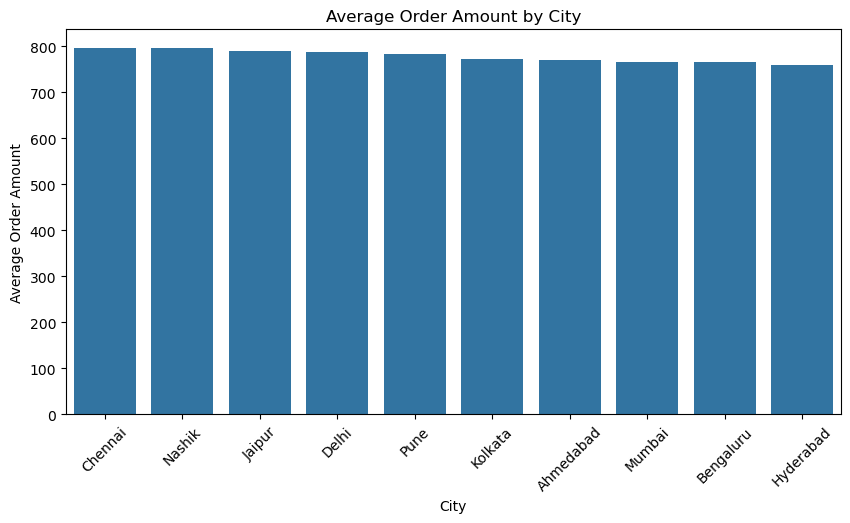

In [56]:
plt.figure(figsize=(10, 5))

city_avg_order = (
    df.groupby("city")["order_amount"]
      .mean()
      .sort_values(ascending=False)
)

sns.barplot(
    x=city_avg_order.index,
    y=city_avg_order.values
)

plt.xticks(rotation=45)
plt.title("Average Order Amount by City")
plt.xlabel("City")
plt.ylabel("Average Order Amount")

plt.show()

### Observation

- Chennai has the highest average order amount, at approximately ₹798.
- Nashik and Jaipur also show relatively high average order amounts.
- Hyderabad has a comparatively lower average order amount.
- Overall, the difference in average order amount across cities is relatively small.

# 3. Delivery Distance vs Actual Delivery Time

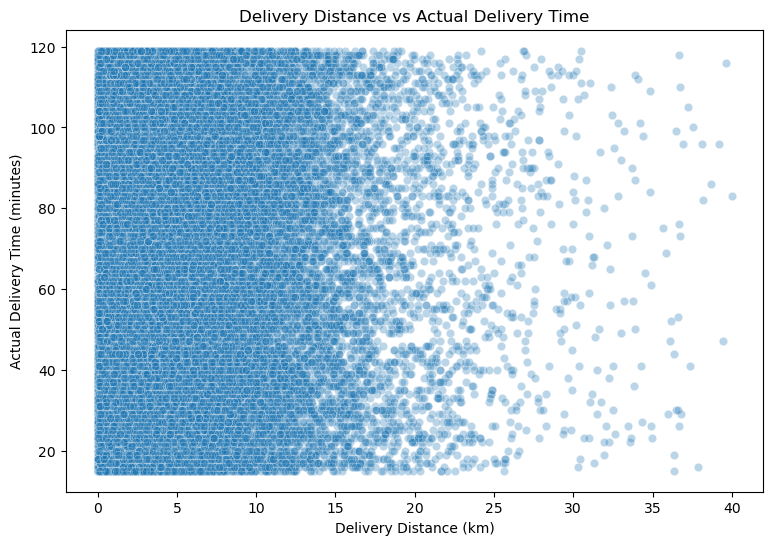

In [57]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="delivery_distance_km",
    y="actual_delivery_min",
    alpha=0.3
)

plt.title("Delivery Distance vs Actual Delivery Time")
plt.xlabel("Delivery Distance (km)")
plt.ylabel("Actual Delivery Time (minutes)")

plt.show()

### Observation

- Most orders have delivery distances below approximately 15 km.
- Actual delivery time varies considerably across different delivery distances.
- A clear strong linear relationship between delivery distance and actual delivery time is not visible from the scatter plot.
- Some longer-distance deliveries also have relatively low delivery times, indicating that distance alone does not determine actual delivery time.

## 4. Estimated vs Actual Delivery Time

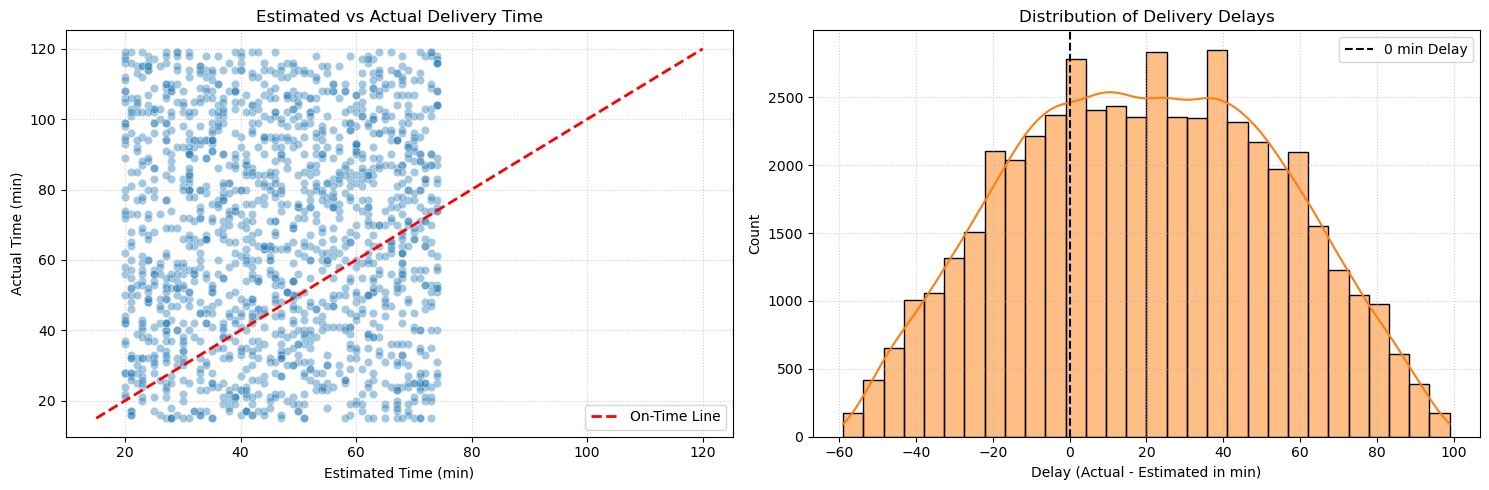

In [58]:
# 1. Feature Engineering: Calculate delay in minutes
df["delivery_delay_min"] = (
    df["actual_delivery_min"] - df["estimated_delivery_min"]
)

# 2. Visualizations
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot A: Estimated vs Actual Time
sns.scatterplot(
    data=df.sample(1500, random_state=42),
    x="estimated_delivery_min",
    y="actual_delivery_min",
    alpha=0.4,
    color="#1f77b4",
    ax=axes[0],
)
axes[0].plot([15, 120], [15, 120], "r--", linewidth=2, label="On-Time Line")
axes[0].set_title("Estimated vs Actual Delivery Time")
axes[0].set_xlabel("Estimated Time (min)")
axes[0].set_ylabel("Actual Time (min)")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

# Plot B: Delivery Delay Distribution
sns.histplot(
    df["delivery_delay_min"], kde=True, bins=30, color="#ff7f0e", ax=axes[1]
)
axes[1].axvline(0, color="black", linestyle="--", label="0 min Delay")
axes[1].set_title("Distribution of Delivery Delays")
axes[1].set_xlabel("Delay (Actual - Estimated in min)")
axes[1].legend()
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

### Observation

- The scatter plot shows considerable variation between estimated and actual delivery times.
- Many orders have actual delivery times different from their estimated delivery times.
- The points are widely scattered, indicating that estimated delivery time does not always closely match the actual delivery time.
- Therefore, a strong linear relationship is not clearly visible between the two variables.

# 5. Discount vs Order Amount

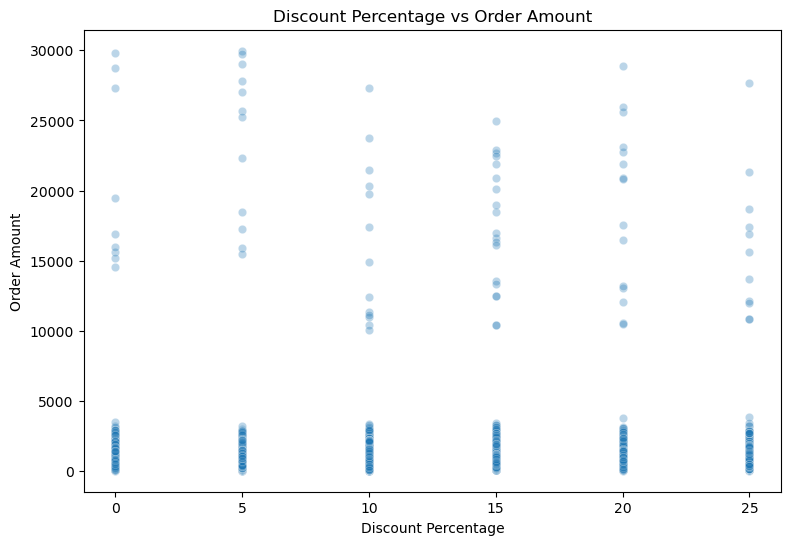

In [59]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="discount_percent",
    y="order_amount",
    alpha=0.3
)

plt.title("Discount Percentage vs Order Amount")
plt.xlabel("Discount Percentage")
plt.ylabel("Order Amount")

plt.show()

### Observation

- Discount percentages are mainly distributed across 0%, 5%, 10%, 15%, 20%, and 25%.
- Order amounts show considerable variation at each discount level.
- Some high-value orders are present across different discount levels.
- No clear increasing or decreasing relationship between discount percentage and order amount is visible from the scatter plot.

# 6. Payment Method vs Average Order Amount

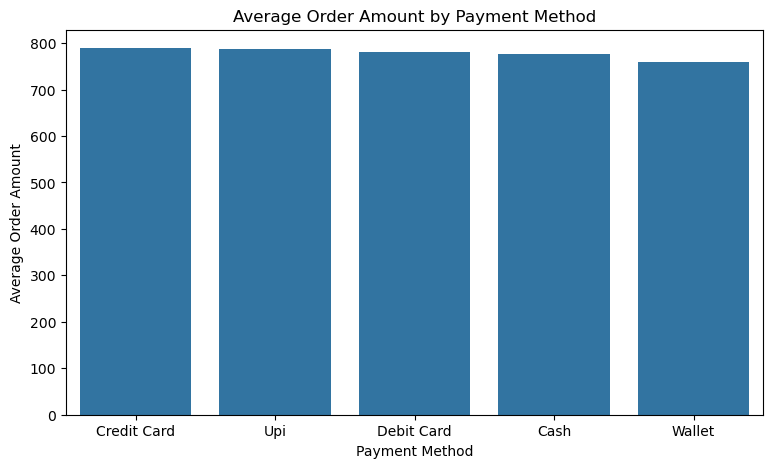

In [60]:
plt.figure(figsize=(9, 5))

payment_avg_order = (
    df.groupby("payment_method")["order_amount"]
      .mean()
      .sort_values(ascending=False)
)

sns.barplot(
    x=payment_avg_order.index,
    y=payment_avg_order.values
)

plt.title("Average Order Amount by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Average Order Amount")

plt.show()

### Observation

- Credit Card users have the highest average order amount, at approximately ₹790.
- UPI users show a similar average order amount, slightly below Credit Card users.
- Debit Card and Cash have moderately lower average order amounts.
- Wallet users have the lowest average order amount, at approximately ₹760.
- Overall, the difference in average order amount across payment methods is relatively small.

# Rating vs Delivery Delay

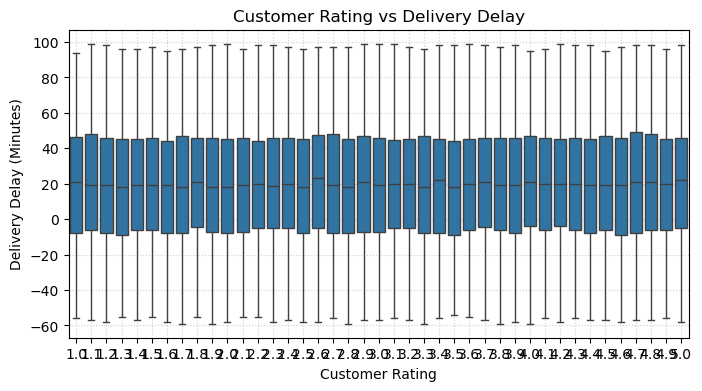

In [61]:
# Rating vs Delivery Delay
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='customer_rating', y='delivery_delay_min')
plt.title('Customer Rating vs Delivery Delay')
plt.xlabel('Customer Rating')
plt.ylabel('Delivery Delay (Minutes)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Observation

- The distribution of delivery delay is relatively similar across different customer rating levels.
- The median delivery delay remains around 20–25 minutes across most rating groups.
- No clear pattern shows that higher delivery delays consistently lead to lower customer ratings.
- Therefore, a strong visible relationship between customer rating and delivery delay is not observed.

# 🔥  Correlation Analysis

In [62]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

correlation

,order_amount,discount_percent,delivery_fee,delivery_distance_km,estimated_delivery_min,actual_delivery_min,customer_rating,restaurant_rating,customer_age,delivery_delay_min
order_amount,1.000000,0.002859,0.003058,0.002496,-0.003812,-0.003029,0.009723,-0.001577,0.001053,-0.000920
discount_percent,0.002859,1.000000,0.001962,0.001902,-0.002918,0.001771,-0.001843,-0.000177,-0.002122,0.002924
delivery_fee,0.003058,0.001962,1.000000,0.001750,0.000699,0.002353,0.001510,-0.004372,0.006107,0.001765
delivery_distance_km,0.002496,0.001902,0.001750,1.000000,0.001549,-0.001145,-0.004873,-0.005357,0.000050,-0.001734
estimated_delivery_min,-0.003812,-0.002918,0.000699,0.001549,1.000000,0.002970,-0.004816,0.001675,0.006054,-0.460958
actual_delivery_min,-0.003029,0.001771,0.002353,-0.001145,0.002970,1.000000,0.003878,-0.002605,0.007257,0.886049
customer_rating,0.009723,-0.001843,0.001510,-0.004873,-0.004816,0.003878,1.000000,-0.005584,-0.000368,0.005675
restaurant_rating,-0.001577,-0.000177,-0.004372,-0.005357,0.001675,-0.002605,-0.005584,1.000000,-0.000315,-0.003088
customer_age,0.001053,-0.002122,0.006107,0.000050,0.006054,0.007257,-0.000368,-0.000315,1.000000,0.003633
delivery_delay_min,-0.000920,0.002924,0.001765,-0.001734,-0.460958,0.886049,0.005675,-0.003088,0.003633,1.000000


# Heatmap

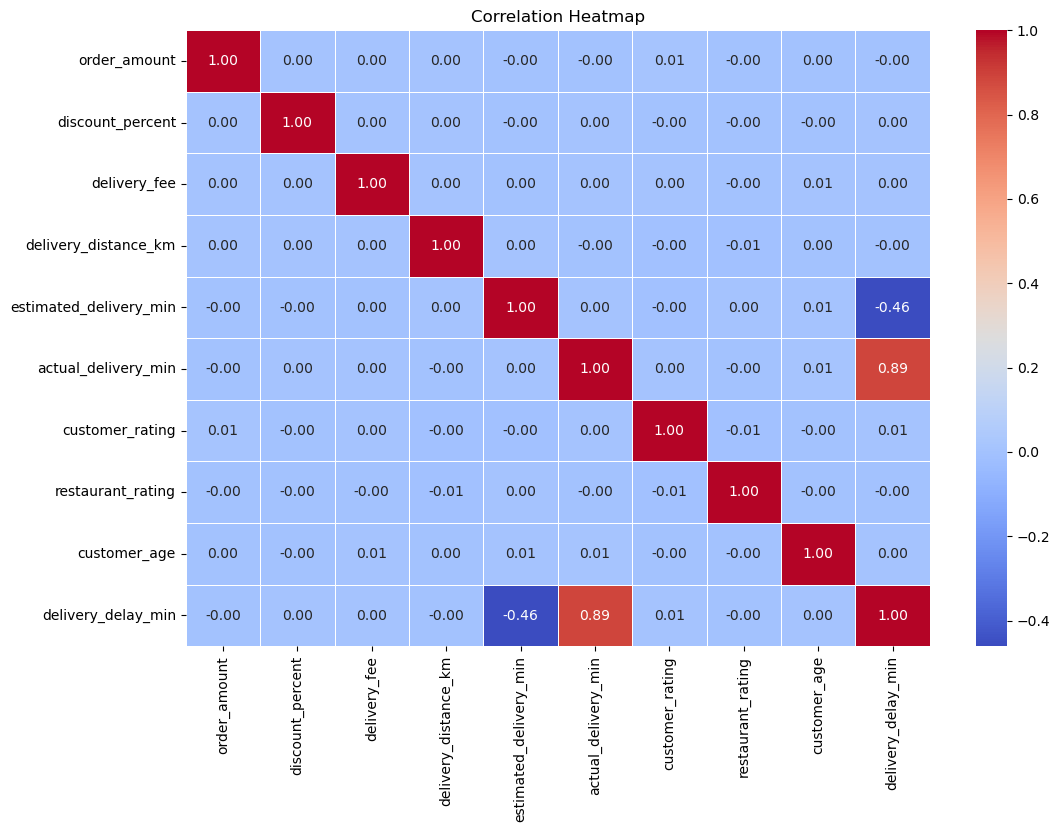

In [63]:
correlation = df.select_dtypes(include="number").corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()

# 📊  MULTIVARIATE ANALYSIS 

### 1. Delivery Distance vs Actual Time by Order Status

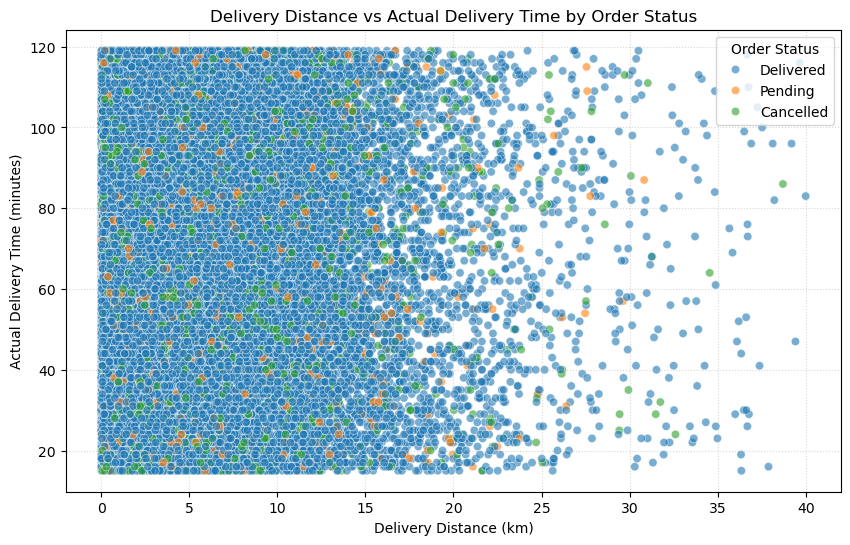

In [64]:
# Delivery Distance vs Actual Time by Order Status

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="delivery_distance_km",
    y="actual_delivery_min",
    hue="order_status",
    alpha=0.6
)

plt.title("Delivery Distance vs Actual Delivery Time by Order Status")
plt.xlabel("Delivery Distance (km)")
plt.ylabel("Actual Delivery Time (minutes)")
plt.legend(title="Order Status")
plt.grid(True, linestyle=":", alpha=0.5)
plt.show()

# Observation 
The scatter plot shows that actual delivery time varies considerably across different delivery distances. Delivered orders are the majority of observations, while pending and cancelled orders are comparatively fewer. There is a general tendency for delivery time to increase as delivery distance increases, although the relationship is not very strong because delivery times vary widely even for similar distances.

# 2. Food Category, Gender and Order Amount

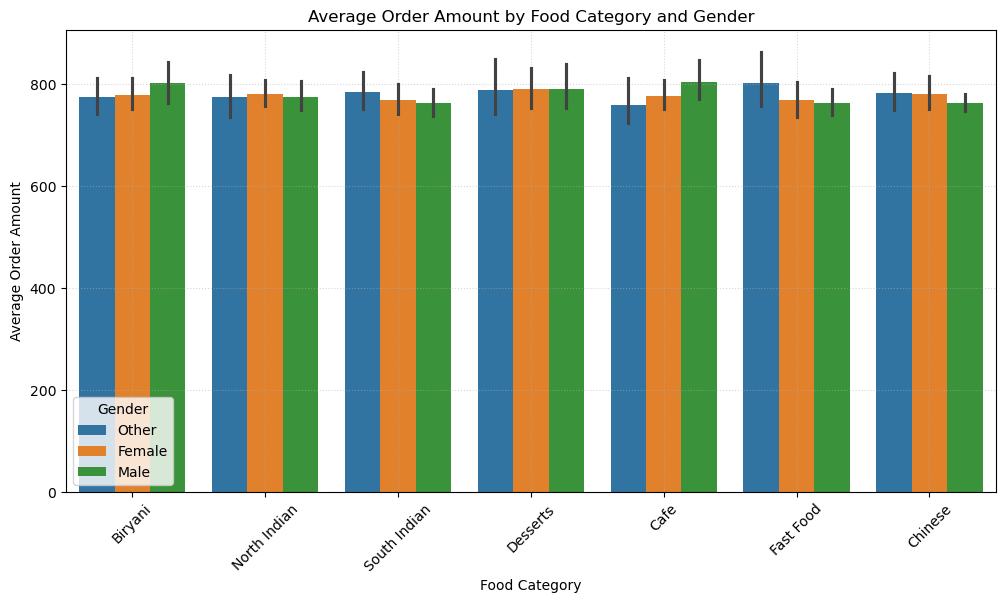

In [65]:
# Food Category, Gender and Order Amount

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x="food_category",
    y="order_amount",
    hue="customer_gender",
    estimator="mean"
)

plt.title("Average Order Amount by Food Category and Gender")
plt.xlabel("Food Category")
plt.ylabel("Average Order Amount")
plt.xticks(rotation=45)
plt.legend(title="Gender")
plt.grid(True, linestyle=":", alpha=0.5)
plt.show()

# Observation: 
Average order amount varies across food categories and gender groups. Male customers show the highest average order amount in Biryani, Café, and Desserts, while Other customers show the highest average in South Indian and Fast Food. Female customers have relatively higher average spending in North Indian and Chinese categories.

# 3. City, Food Category and Order Amount

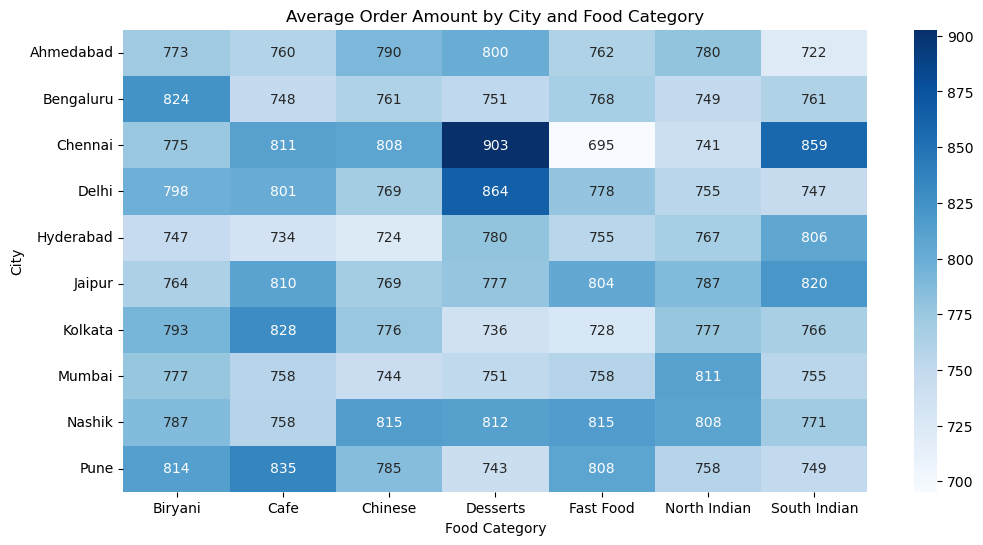

In [66]:
# City, Food Category and Order Amount

city_food = df.pivot_table(
    values="order_amount",
    index="city",
    columns="food_category",
    aggfunc="mean"
)

plt.figure(figsize=(12, 6))

sns.heatmap(
    city_food,
    annot=True,
    fmt=".0f",
    cmap="Blues"
)

plt.title("Average Order Amount by City and Food Category")
plt.xlabel("Food Category")
plt.ylabel("City")
plt.show()

# Observation:
Average order amount varies across cities and food categories. Chennai–Desserts has the highest average order amount at approximately ₹903, followed by Chennai–South Indian (₹859) and Delhi–Desserts (₹864). Hyderabad generally shows comparatively lower average order amounts across several food categories.

# 📋️ PIVOT TABLES

## Pivot Table 1: City-wise Order Amount

In [67]:
# Pivot Table 1: City-wise Order Amount

pivot_city = pd.pivot_table(
    df,
    index="city",
    values="order_amount",
    aggfunc=["count", "mean", "sum"]
)

pivot_city

,count,mean,sum
,order_amount,order_amount,order_amount
city,,,
Ahmedabad,3447,769.789365,2.653464e+06
Bengaluru,3487,765.618631,2.669712e+06
Chennai,3418,796.535656,2.722559e+06
Delhi,6863,786.523228,5.397909e+06
Hyderabad,3420,759.724225,2.598257e+06
Jaipur,3418,790.258673,2.701104e+06
Kolkata,3441,772.721215,2.658934e+06
Mumbai,8456,765.860969,6.476120e+06


# Observation

Chennai has the highest average order amount (₹796.54), closely followed by Nashik (₹796.04), while Hyderabad has the lowest average order amount (₹759.72). Mumbai has the highest number of orders (8,456).

## Pivot Table 2: Food Category Performance

In [68]:
# Pivot Table 2: Food Category Performance

pivot_food = pd.pivot_table(
    df,
    index="food_category",
    values="order_amount",
    aggfunc=["count", "mean", "sum"]
)

pivot_food

,count,mean,sum
,order_amount,order_amount,order_amount
food_category,,,
Biryani,6887,787.107724,5.420811e+06
Cafe,6953,785.078796,5.458653e+06
Chinese,6887,774.604234,5.334699e+06
Desserts,6854,790.345291,5.417027e+06
Fast Food,6858,773.076315,5.301757e+06
North Indian,8484,776.958169,6.591713e+06
South Indian,6828,769.510231,5.254216e+06


# Observation — 

Desserts has the highest average order amount at ₹790.35, followed by Biryani at ₹787.11. South Indian has the lowest average order amount at ₹769.51. North Indian has the highest number of orders (8,484) and also the highest total order amount (₹6.59 million).

## Pivot Table 3: Payment Method vs Order Status

In [69]:
# Pivot Table 3: Payment Method vs Order Status

pivot_payment_status = pd.pivot_table(
    df,
    index="payment_method",
    columns="order_status",
    values="order_id",
    aggfunc="count",
    fill_value=0
)

pivot_payment_status

order_status,Cancelled,Delivered,Pending
payment_method,,,
Cash,1074,12029,537
Credit Card,523,6013,261
Debit Card,532,6143,254
Upi,1290,13532,622
Wallet,529,6130,282


# Observation
- UPI has the highest number of orders across all statuses, with 13,532 Delivered, 1,290 Cancelled, and 622 Pending orders.
- Cash is the second-highest payment method by order volume, with 12,029 Delivered orders.
- Credit Card has the lowest overall order volume among the payment methods shown.

## Pivot Table 4: City vs Average Delivery Time

In [70]:
# Pivot Table 4: City vs Average Delivery Time

pivot_city_delivery = pd.pivot_table(
    df,
    index="city",
    values="actual_delivery_min",
    aggfunc=["count", "mean"]
)

pivot_city_delivery

,count,mean
,actual_delivery_min,actual_delivery_min
city,,
Ahmedabad,3447,67.060342
Bengaluru,3487,66.638371
Chennai,3418,66.566413
Delhi,6863,66.398368
Hyderabad,3420,66.538012
Jaipur,3418,66.595377
Kolkata,3441,67.217379
Mumbai,8456,66.629257


# Observation

Kolkata has the highest average actual delivery time at 67.22 minutes, followed by Ahmedabad at 67.06 minutes. Delhi has the lowest average delivery time at 66.40 minutes. Mumbai has the highest number of orders (8,456).

# Key Business Questions

-  You can answer these after running the analysis.



## Question 1
### Which city has the highest number of orders?

In [86]:
df["city"].value_counts().head()

city
Mumbai       8456
Pune         6939
Delhi        6863
Nashik       6862
Bengaluru    3487
Name: count, dtype: int64

## Question 2
### Which food category is ordered the most

In [87]:
df["food_category"].value_counts()

food_category
North Indian    8484
Cafe            6953
Biryani         6887
Chinese         6887
Fast Food       6858
Desserts        6854
South Indian    6828
Name: count, dtype: int64

## Question 3
### Which city generates the highest total revenue?

In [73]:
df.groupby("city")["order_amount"].sum().sort_values(ascending=False)

city
Mumbai       6.476120e+06
Nashik       5.462402e+06
Pune         5.438415e+06
Delhi        5.397909e+06
Chennai      2.722559e+06
Jaipur       2.701104e+06
Bengaluru    2.669712e+06
Kolkata      2.658934e+06
Ahmedabad    2.653464e+06
Hyderabad    2.598257e+06
Name: order_amount, dtype: float64

## Question 4
### Which food category generates the highest revenue?

In [74]:
df.groupby("food_category")["order_amount"].sum().sort_values(ascending=False)

food_category
North Indian    6.591713e+06
Cafe            5.458653e+06
Biryani         5.420811e+06
Desserts        5.417027e+06
Chinese         5.334699e+06
Fast Food       5.301757e+06
South Indian    5.254216e+06
Name: order_amount, dtype: float64

## Question 5
### Which food category has the highest average order amount?

In [75]:
df.groupby("food_category")["order_amount"].mean().sort_values(ascending=False)

food_category
Desserts        790.345291
Biryani         787.107724
Cafe            785.078796
North Indian    776.958169
Chinese         774.604234
Fast Food       773.076315
South Indian    769.510231
Name: order_amount, dtype: float64

## Question 6
### Which city has the highest average delivery time?

In [76]:
df.groupby("city")["actual_delivery_min"].mean().sort_values(ascending=False)

city
Kolkata      67.217379
Ahmedabad    67.060342
Pune         66.892203
Nashik       66.743806
Bengaluru    66.638371
Mumbai       66.629257
Jaipur       66.595377
Chennai      66.566413
Hyderabad    66.538012
Delhi        66.398368
Name: actual_delivery_min, dtype: float64

## Question 7
### What is the most preferred payment method?

In [77]:
df["payment_method"].value_counts()

payment_method
Upi            15444
Cash           13640
Wallet          6941
Debit Card      6929
Credit Card     6797
Name: count, dtype: int64

## Question 8
### How much does actual delivery time differ from estimated delivery time?

In [89]:
df["delivery_time_difference"] = (df["actual_delivery_min"] -df["estimated_delivery_min"])
df["delivery_time_difference"].describe()

count    49751.000000
mean        19.697956
std         34.244687
min        -59.000000
25%         -7.000000
50%         20.000000
75%         46.000000
max         99.000000
Name: delivery_time_difference, dtype: float64

## Question 9
### Which cities have the largest delivery delays?

In [82]:
df.groupby("city")[
    "delivery_time_difference"
].mean().sort_values(ascending=False) 

city
Ahmedabad    20.599072
Kolkata      20.045917
Jaipur       19.958163
Pune         19.837873
Chennai      19.814804
Hyderabad    19.655556
Mumbai       19.569063
Delhi        19.422556
Nashik       19.397406
Bengaluru    19.303413
Name: delivery_time_difference, dtype: float64

## Question 10
### Which customer age group spends the most?

First create age groups:

In [84]:
df["age_group"] = pd.cut(df["customer_age"],bins=[0, 25, 35, 45, 55, 100],
        labels=["18-25","26-35","36-45","46-55","56+"])
df.groupby("age_group", observed=False)["order_amount"].mean().sort_values(ascending=False)

age_group
36-45    788.335977
56+      781.199038
18-25    781.119774
46-55    771.943511
26-35    771.462858
Name: order_amount, dtype: float64

# 💡 Final Insights Section

#### ⚠️ Important: Final numerical insights should be generated after running the complete cleaned notebook. Don't write numbers manually before checking the final output.

- Your final insights can be structured like this:

## 🔍 Top Business Insights

1. The analysis identified the city with the highest number of food orders.

2. The most popular food category was identified based on total order frequency.

3. Revenue analysis revealed which city and food category contribute the most to overall order value.

4. Delivery analysis showed the relationship between delivery distance and actual delivery time.

5. Comparison between estimated and actual delivery time helped identify possible delivery delays.

6. Payment method analysis revealed customer payment preferences.

7. Discount analysis helped understand whether higher discounts are associated with higher order values.

8. Customer age analysis identified important customer spending patterns.

9. Restaurant rating and customer rating analysis provided insights into customer satisfaction.

10. Data cleaning revealed missing values, duplicate records, inconsistent categorical values, and unrealistic values that required logical treatment.

## 🚀 Business Recommendations

###  💼 Business Recommendations

1. Focus promotional campaigns on high-performing food categories.

2. Improve delivery operations in cities with higher average delivery delays.

3. Analyze restaurants with low customer ratings and identify areas for improvement.

4. Use customer ordering patterns to create targeted offers and discounts.

5. Optimize delivery routes to reduce delivery time for long-distance orders.

6. Promote preferred payment methods while ensuring smooth payment experiences.

7. Encourage high-value customers through loyalty programs and personalized offers.

8. Monitor the difference between estimated and actual delivery times to improve delivery accuracy.

9. Use city-wise demand analysis for better restaurant partnerships and delivery resource allocation.

10. Continuously monitor data quality to prevent inconsistent values and duplicate records.

# 🏁 Conclusion

This Exploratory Data Analysis project examined the Indian Food Delivery dataset to understand customer behavior, food preferences, order patterns, delivery performance, ratings, and business performance.

The analysis included data cleaning, missing value treatment, duplicate removal, inconsistency correction, outlier detection, and detailed univariate, bivariate, and multivariate analysis.

The project provides useful insights that can help food delivery businesses improve operational efficiency, understand customer preferences, optimize delivery performance, and make data-driven business decisions.